# MatFuse: sample materials and map inventory

This analysis covers the five material samples distributed with the upstream MatFuse repository. Source metadata tags are retained without modification. The tables and figures describe sample composition and storage requirements.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: Fitwell-AI


In [2]:
samples = pd.read_csv(ROOT / "datasets/matfuse/samples.csv")
files = pd.read_csv(ROOT / "datasets/matfuse/files.csv")
files["sample_id"] = files["path"].str.split("/").str[1]
files["file_type"] = files["path"].str.rsplit("/", n=1).str[-1]
assert len(samples) == 5 and len(files) == 35
summary = files.groupby("sample_id").agg(file_count=("path", "size"), total_bytes=("size_bytes", "sum"))
print(samples[["sample_id", "tags"]].to_string(index=False))
print("\nFile inventory:")
print(summary.to_string())
assert summary.file_count.eq(7).all()
assert int(summary.total_bytes.sum()) == 2148395

     sample_id                         tags
 asphalt_floor asphalt;floor;concrete;grass
  castle_brick brick;wall;castle;terracotta
 clean_pebbles   pebbles;clean;stones;small
     grey_roof          roof;tiles;grey;old
old_wood_floor          wood;floor;old;dark

File inventory:
                file_count  total_bytes
sample_id                              
asphalt_floor            7       502233
castle_brick             7       544078
clean_pebbles            7       420637
grey_roof                7       302744
old_wood_floor           7       378703


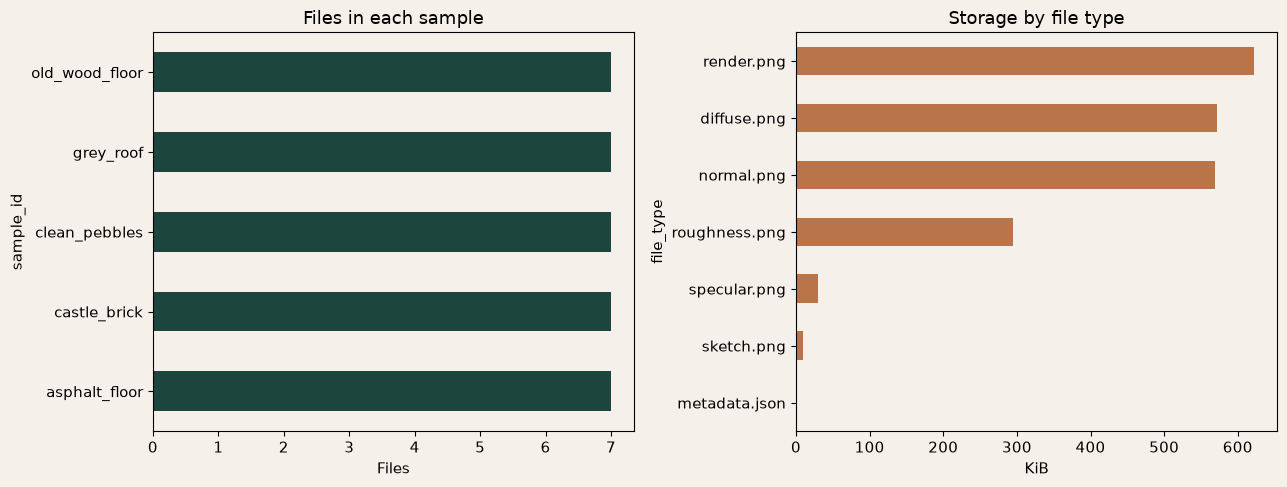

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
summary["file_count"].plot.barh(ax=axes[0], color="#1c463d")
axes[0].set_title("Files in each sample")
axes[0].set_xlabel("Files")
(files.groupby("file_type")["size_bytes"].sum() / 1024).sort_values().plot.barh(ax=axes[1], color="#b97449")
axes[1].set_title("Storage by file type")
axes[1].set_xlabel("KiB")
plt.tight_layout()
plt.show()

## Interpretation

Diffuse, normal, roughness and specular maps represent different rendering properties. Their roles differ from ordinary RGB scene photographs and must be considered during dataset preparation. The full MatFuse training set is not included; the available samples support structural analysis rather than broad recognition benchmarking.